# Business-Oriented Exploratory Data Analysis (EDA)

## Objective

The objective of this phase is to analyze customer characteristics and identify the factors associated with loan default.

Using the preprocessed dataset, this analysis aims to answer key business questions related to customer demographics, financial behavior, debt burden, credit utilization, and repayment history.

The insights obtained from this analysis will improve our understanding of credit risk, guide feature engineering, and support the development of an effective credit default prediction model.

# 1. Target Variable Analysis

## Business Question

What proportion of customers defaulted on their loans?

Understanding the distribution of the target variable is essential for estimating the baseline credit risk and determining whether the dataset is balanced. This also influences the choice of evaluation metrics and modeling techniques.

In [3]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df = pd.read_csv("../Data/Processed/credit_cleaned.csv")

# Create a copy for analysis
credit_clean = df.copy()

In [5]:
# Target distribution
target_counts = credit_clean["SeriousDlqin2yrs"].value_counts().sort_index()

target_percent = (
    credit_clean["SeriousDlqin2yrs"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percent.round(2)
})

target_summary

,Count,Percentage (%)
SeriousDlqin2yrs,,
0,139973,93.32
1,10026,6.68


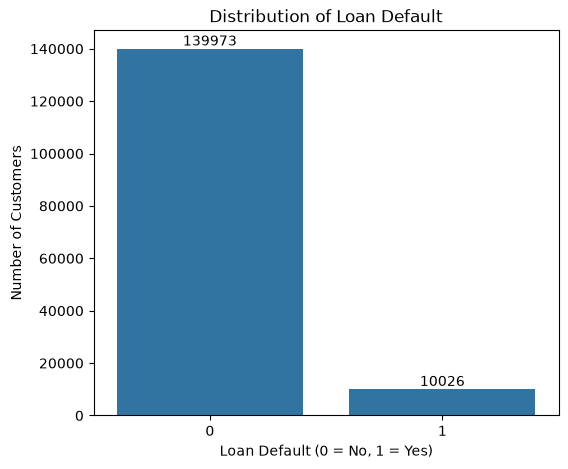

In [6]:
plt.figure(figsize=(6, 5))

ax = sns.countplot(
    data=credit_clean,
    x="SeriousDlqin2yrs"
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Loan Default")
plt.xlabel("Loan Default (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

### Business Interpretation

Approximately **93%** of customers did not default on their loans, while **7%** experienced serious delinquency within two years.

This indicates that loan defaults are relatively uncommon, resulting in a **highly imbalanced dataset**.

From a business perspective, correctly identifying the minority class (customers likely to default) is more valuable than simply achieving high overall accuracy. Consequently, evaluation metrics such as **Precision, Recall, F1-score, and ROC-AUC** will be more informative than accuracy alone during model evaluation.

## 2. Age and Default Risk

### Business Question

Does customer age influence the likelihood of loan default?

Age may influence financial stability, credit history, and repayment capacity. We will compare age characteristics between customers who defaulted and those who did not, followed by an analysis of default rates across age groups.

In [7]:
credit_clean.groupby("SeriousDlqin2yrs")["age"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
SeriousDlqin2yrs,,,,
0,139973,52.75,52.0,14.79
1,10026,45.93,45.0,12.92


In [8]:
credit_clean["AgeGroup"] = pd.cut(
    credit_clean["age"],
    bins=[20, 30, 40, 50, 60, 70, 80, 110],
    labels=[
        "21-30",
        "31-40",
        "41-50",
        "51-60",
        "61-70",
        "71-80",
        "81+"
    ]
)
age_default = (
    credit_clean.groupby("AgeGroup", observed=True)["SeriousDlqin2yrs"]
    .agg(["count", "sum", "mean"])
)

age_default["default_rate_%"] = age_default["mean"] * 100

age_default

,count,sum,mean,default_rate_%
AgeGroup,,,,
21-30,10757,1244,0.115646,11.564563
31-40,24339,2390,0.098196,9.819631
41-50,35037,2893,0.082570,8.256985
51-60,34806,2149,0.061742,6.174223
61-70,27424,952,0.034714,3.471412
71-80,12700,298,0.023465,2.346457
81+,4936,100,0.020259,2.025932


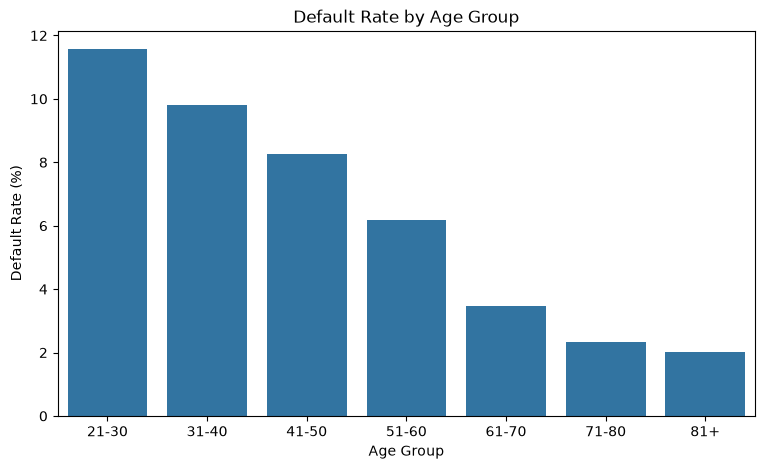

In [9]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_default.index,
    y=age_default["default_rate_%"]
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")

plt.show()

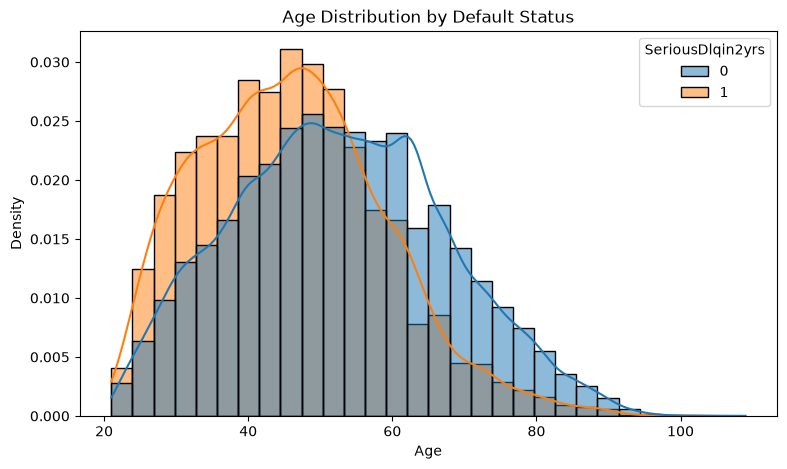

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=credit_clean,
    x="age",
    hue="SeriousDlqin2yrs",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False
)

plt.title("Age Distribution by Default Status")
plt.xlabel("Age")
plt.ylabel("Density")

plt.show()

### Business Finding

The analysis shows a clear inverse relationship between age and default rate. Customers in the **21–30 age group have the highest default rate at 11.56%**, while customers aged **81+ have the lowest rate at 2.03%**.

Default rates decline consistently across successive age groups, indicating that younger customers in this dataset are associated with substantially higher credit risk.

However, this analysis identifies an association rather than causation. Other factors such as income, debt burden, and repayment history may also contribute to the observed relationship.

# 3. Monthly Income and Default Risk

## Business Question

Does monthly income influence the likelihood of loan default?

Higher income may indicate greater repayment capacity; however, income alone may not determine credit risk because debt obligations and credit utilization also affect a customer's ability to repay.

We will compare income characteristics between defaulters and non-defaulters and analyze default rates across income groups.

In [12]:
credit_clean.groupby("SeriousDlqin2yrs")["MonthlyIncome"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
SeriousDlqin2yrs,,,,
0,139973,6477.63,5400.0,13256.65
1,10026,5592.40,5240.0,5635.26


In [13]:
credit_clean["IncomeGroup"] = pd.qcut(
    credit_clean["MonthlyIncome"],
    q=5,
    duplicates="drop"
)

In [14]:
income_default = (
    credit_clean.groupby("IncomeGroup", observed=True)["SeriousDlqin2yrs"]
    .agg(["count", "sum", "mean"])
)

income_default["default_rate_%"] = income_default["mean"] * 100

income_default


,count,sum,mean,default_rate_%
IncomeGroup,,,,
"(-0.001, 3400.0]",30289,2789,0.092080,9.207963
"(3400.0, 5400.0]",59757,4031,0.067457,6.745653
"(5400.0, 8250.0]",29960,1819,0.060714,6.071429
"(8250.0, 3008750.0]",29993,1387,0.046244,4.624412


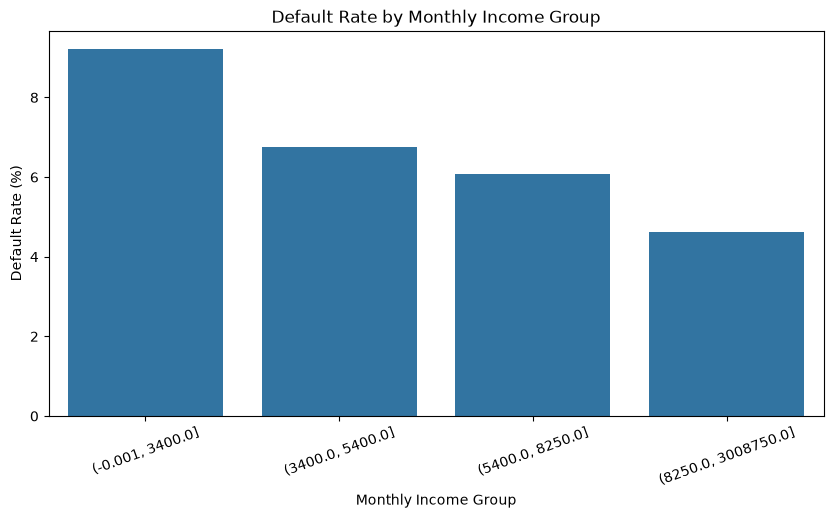

In [15]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=income_default.index.astype(str),
    y=income_default["default_rate_%"]
)

plt.title("Default Rate by Monthly Income Group")
plt.xlabel("Monthly Income Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)

plt.show()

### Business Finding

The analysis shows an inverse relationship between monthly income and default rate.

Customers with monthly income of **3,400 or below have the highest default rate at 9.21%**, while customers earning **more than 8,250 have the lowest default rate at 4.62%**.

Overall, default rates decline as monthly income increases, suggesting that customers with higher reported income are associated with lower credit risk in this dataset.

However, income should not be considered independently because a customer's ability to repay also depends on factors such as debt obligations, credit utilization, and previous repayment behavior.

# 4. Debt Ratio and Default Risk

## Business Question

Does a higher debt ratio correspond to a higher likelihood of loan default?

Debt ratio represents the customer's debt obligations relative to their reported income. A higher ratio may indicate greater financial burden and potentially lower repayment capacity.

We will examine default rates across different debt-ratio ranges to determine whether debt burden is associated with credit risk.

In [18]:
credit_clean["DebtRatioGroup"] = pd.cut(
    credit_clean["DebtRatio"],
    bins=[-1, 0.2, 0.5, 1, 2, float("inf")],
    labels=[
        "≤ 0.2",
        "0.2–0.5",
        "0.5–1",
        "1–2",
        "> 2"
    ]
)

In [19]:
debt_default = (
    credit_clean.groupby("DebtRatioGroup", observed=True)["SeriousDlqin2yrs"]
    .agg(["count", "sum", "mean"])
)

debt_default["default_rate_%"] = debt_default["mean"] * 100

debt_default

,count,sum,mean,default_rate_%
DebtRatioGroup,,,,
≤ 0.2,42289,2585,0.061127,6.112701
0.2–0.5,51418,3070,0.059707,5.970672
0.5–1,21155,2080,0.098322,9.832191
1–2,4092,539,0.131720,13.172043
> 2,31045,1752,0.056434,5.643421


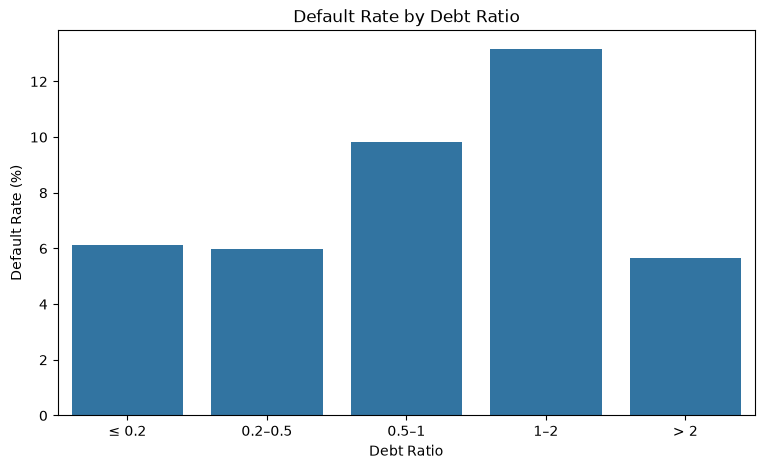

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=debt_default.index,
    y=debt_default["default_rate_%"]
)

plt.title("Default Rate by Debt Ratio")
plt.xlabel("Debt Ratio")
plt.ylabel("Default Rate (%)")

plt.show()

In [21]:
credit_clean["DebtRatioGroup2"] = pd.cut(
    credit_clean["DebtRatio"],
    bins=[-1, 0.2, 0.5, 1, 2, 5, 10, 50, 100, 1000, float("inf")],
    labels=[
        "≤ 0.2",
        "0.2–0.5",
        "0.5–1",
        "1–2",
        "2–5",
        "5–10",
        "10–50",
        "50–100",
        "100–1000",
        ">1000"
    ]
)

debt_default2 = (
    credit_clean.groupby(
        "DebtRatioGroup2",
        observed=True
    )["SeriousDlqin2yrs"]
    .agg(["count", "sum", "mean"])
)

debt_default2["default_rate_%"] = (
    debt_default2["mean"] * 100
).round(2)

debt_default2

,count,sum,mean,default_rate_%
DebtRatioGroup2,,,,
≤ 0.2,42289,2585,0.061127,6.11
0.2–0.5,51418,3070,0.059707,5.97
0.5–1,21155,2080,0.098322,9.83
1–2,4092,539,0.131720,13.17
2–5,1399,110,0.078628,7.86
5–10,769,33,0.042913,4.29
10–50,2943,131,0.044512,4.45
50–100,1554,68,0.043758,4.38
100–1000,7488,581,0.077591,7.76


### Business Finding

Debt ratio shows a **non-linear and irregular relationship** with default risk.

Default rates increase from approximately **6% at lower debt ratios to 9.83% for the 0.5–1 range and peak at 13.17% for customers with a debt ratio between 1 and 2**.

However, default rates decline for extremely high debt-ratio values. This suggests that the extreme tail of the `DebtRatio` distribution may behave differently from the normal range, potentially due to unusual or very low reported income values identified during data-quality analysis.

Therefore, `DebtRatio` appears to contain useful information about credit risk, but its relationship with default is **not simply linear or monotonic**.

# 5. Credit Utilization and Default Risk

## Business Question

Does higher revolving credit utilization correspond to a higher likelihood of loan default?

Revolving credit utilization represents the extent to which a customer is using their available unsecured revolving credit. Higher utilization may indicate greater dependence on available credit and potentially higher financial stress.

We will analyze default rates across different utilization levels to determine whether credit utilization is associated with default risk.

In [22]:
credit_clean["UtilizationGroup"] = pd.cut(
    credit_clean["RevolvingUtilizationOfUnsecuredLines"],
    bins=[-0.001, 0.1, 0.3, 0.5, 0.75, 1, 2, 5, float("inf")],
    labels=[
        "0–0.1",
        "0.1–0.3",
        "0.3–0.5",
        "0.5–0.75",
        "0.75–1",
        "1–2",
        "2–5",
        ">5"
    ]
)

In [23]:
utilization_default = (
    credit_clean.groupby(
        "UtilizationGroup",
        observed=True
    )["SeriousDlqin2yrs"]
    .agg(["count", "sum", "mean"])
)

utilization_default["default_rate_%"] = (
    utilization_default["mean"] * 100
).round(2)

utilization_default

,count,sum,mean,default_rate_%
UtilizationGroup,,,,
0–0.1,64404,1166,0.018104,1.81
0.1–0.3,28478,895,0.031428,3.14
0.3–0.5,15830,926,0.058497,5.85
0.5–0.75,13764,1394,0.101279,10.13
0.75–1,24202,4408,0.182134,18.21
1–2,2950,1183,0.401017,40.10
2–5,117,34,0.290598,29.06
>5,254,20,0.078740,7.87


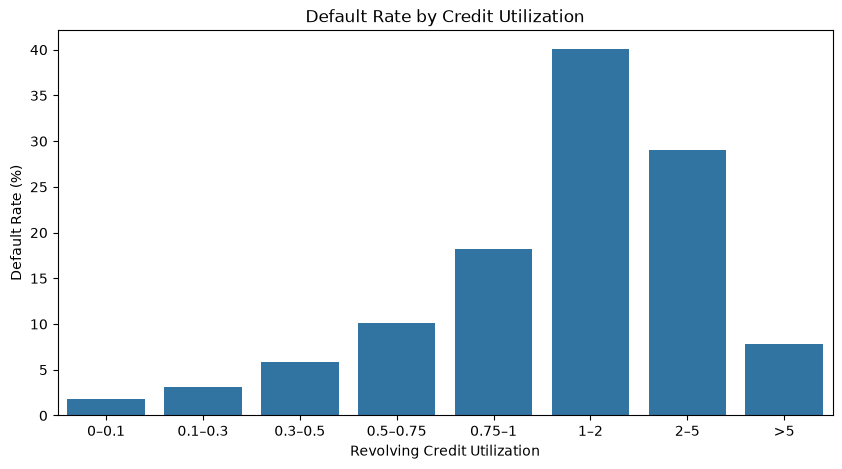

In [24]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=utilization_default.index,
    y=utilization_default["default_rate_%"]
)

plt.title("Default Rate by Credit Utilization")
plt.xlabel("Revolving Credit Utilization")
plt.ylabel("Default Rate (%)")

plt.show()

### Business Finding

Credit utilization shows a strong positive association with default risk within the normal-to-high utilization range.

The default rate increases consistently from **1.81% for customers with utilization between 0–0.1 to 18.21% for customers with utilization between 0.75–1**. It reaches **40.10% for the 1–2 utilization range**.

This indicates that customers using a large proportion of their available revolving credit are associated with substantially higher credit risk.

The relationship becomes irregular beyond a utilization of 2. However, these extreme ranges contain very few observations and were previously identified as extreme values during data-quality analysis. Therefore, the apparent decline in default rate in these ranges should not be interpreted as lower risk.

Overall, credit utilization appears to be a strong indicator of default risk in this dataset.

# 6. Payment History and Default Risk

## Business Question

Does a history of late payments indicate a higher likelihood of future loan default?

Previous payment behavior is an important indicator of creditworthiness. Customers who have repeatedly missed or delayed payments may have a higher probability of experiencing future financial difficulties.

We will examine the relationship between different levels of payment delinquency and the probability of default.

In [25]:
late90_default = (
    credit_clean.groupby("NumberOfTimes90DaysLate")["SeriousDlqin2yrs"]
    .agg(["count", "sum", "mean"])
)

late90_default["default_rate_%"] = (
    late90_default["mean"] * 100
).round(2)

late90_default

,count,sum,mean,default_rate_%
NumberOfTimes90DaysLate,,,,
0.0,141930,6701,0.047213,4.72
1.0,5243,1765,0.336639,33.66
2.0,1555,776,0.499035,49.90
3.0,667,385,0.577211,57.72
4.0,291,195,0.670103,67.01
5.0,131,83,0.633588,63.36
6.0,80,48,0.600000,60.00
7.0,38,31,0.815789,81.58
8.0,21,15,0.714286,71.43


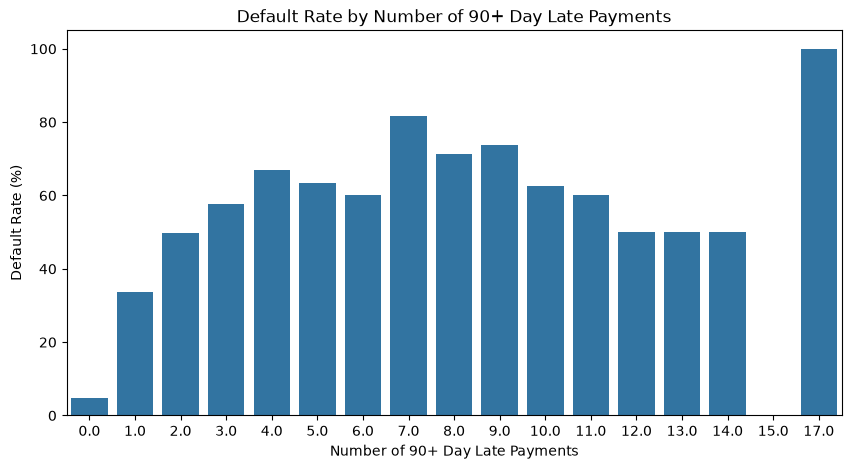

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=late90_default.index,
    y=late90_default["default_rate_%"]
)

plt.title("Default Rate by Number of 90+ Day Late Payments")
plt.xlabel("Number of 90+ Day Late Payments")
plt.ylabel("Default Rate (%)")

plt.show()

In [27]:
late90_default.head(10)

,count,sum,mean,default_rate_%
NumberOfTimes90DaysLate,,,,
0.0,141930,6701,0.047213,4.72
1.0,5243,1765,0.336639,33.66
2.0,1555,776,0.499035,49.90
3.0,667,385,0.577211,57.72
4.0,291,195,0.670103,67.01
5.0,131,83,0.633588,63.36
6.0,80,48,0.600000,60.00
7.0,38,31,0.815789,81.58
8.0,21,15,0.714286,71.43


### Business Finding

Previous 90+ day payment delinquency shows a very strong association with future default risk.

Customers with **no previous 90+ day late payments have a default rate of only 4.72%**, while customers with **one previous 90+ day late payment have a default rate of 33.66%**. The default rate generally remains substantially higher as the number of previous severe delinquencies increases.

At higher delinquency counts, the rates fluctuate because the number of observations becomes very small. Therefore, individual percentages for these rare groups should not be interpreted independently.

Overall, previous severe payment delinquency appears to be one of the strongest indicators of credit risk in this dataset.

In [28]:
delinquency_features = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

for feature in delinquency_features:
    print("\n", "=" * 60)
    print(feature)

    result = (
        credit_clean.groupby(feature)["SeriousDlqin2yrs"]
        .agg(["count", "sum", "mean"])
    )

    result["default_rate_%"] = (result["mean"] * 100).round(2)

    print(result.head(6))


NumberOfTime30-59DaysPastDueNotWorse
                                       count   sum      mean  default_rate_%
NumberOfTime30-59DaysPastDueNotWorse                                        
0.0                                   126287  5188  0.041081            4.11
1.0                                    16032  2409  0.150262           15.03
2.0                                     4598  1219  0.265115           26.51
3.0                                     1754   618  0.352338           35.23
4.0                                      747   318  0.425703           42.57
5.0                                      342   154  0.450292           45.03

NumberOfTime60-89DaysPastDueNotWorse
                                       count   sum      mean  default_rate_%
NumberOfTime60-89DaysPastDueNotWorse                                        
0.0                                   142664  7403  0.051891            5.19
1.0                                     5731  1777  0.310068           31.01


In [29]:
for feature in delinquency_features:

    temp = credit_clean.copy()

    temp["HadDelinquency"] = (
        temp[feature] > 0
    ).astype(int)

    result = (
        temp.groupby("HadDelinquency")["SeriousDlqin2yrs"]
        .agg(["count", "sum", "mean"])
    )

    result["default_rate_%"] = (
        result["mean"] * 100
    ).round(2)

    print("\n", feature)
    print(result)


 NumberOfTime30-59DaysPastDueNotWorse
                 count   sum      mean  default_rate_%
HadDelinquency                                        
0               126287  5188  0.041081            4.11
1                23712  4838  0.204032           20.40

 NumberOfTime60-89DaysPastDueNotWorse
                 count   sum      mean  default_rate_%
HadDelinquency                                        
0               142664  7403  0.051891            5.19
1                 7335  2623  0.357601           35.76

 NumberOfTimes90DaysLate
                 count   sum      mean  default_rate_%
HadDelinquency                                        
0               141930  6701  0.047213            4.72
1                 8069  3325  0.412071           41.21


In [30]:
severity_summary = []

for feature in delinquency_features:

    temp = credit_clean.copy()

    temp["HadDelinquency"] = (
        temp[feature] > 0
    ).astype(int)

    rates = (
        temp.groupby("HadDelinquency")["SeriousDlqin2yrs"]
        .mean() * 100
    )

    severity_summary.append({
        "Delinquency Type": feature,
        "No Delinquency (%)": rates.get(0),
        "Had Delinquency (%)": rates.get(1)
    })

severity_summary = pd.DataFrame(severity_summary)

severity_summary.round(2)

,Delinquency Type,No Delinquency (%),Had Delinquency (%)
0,NumberOfTime30-59DaysPastDueNotWorse,4.11,20.40
1,NumberOfTime60-89DaysPastDueNotWorse,5.19,35.76
2,NumberOfTimes90DaysLate,4.72,41.21


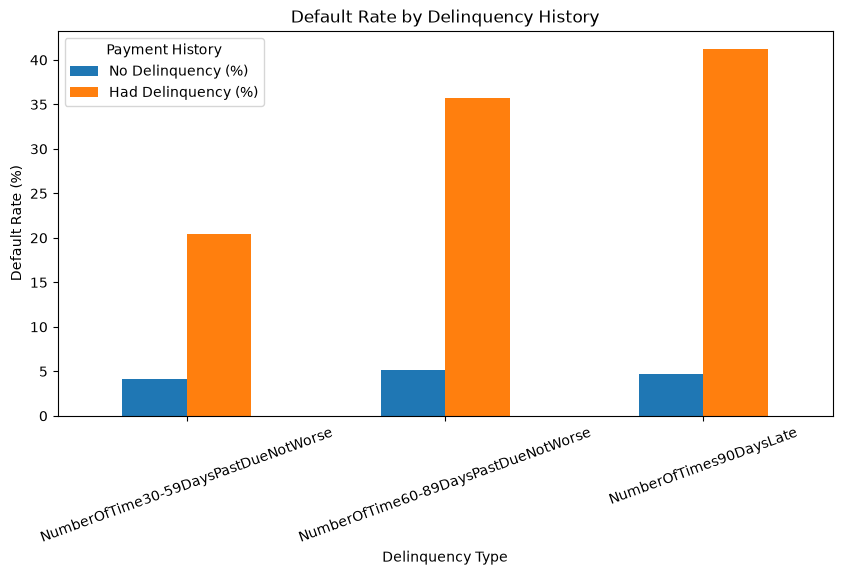

In [31]:
plot_data = severity_summary.set_index(
    "Delinquency Type"
)[
    ["No Delinquency (%)", "Had Delinquency (%)"]
]

plot_data.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Default Rate by Delinquency History")
plt.xlabel("Delinquency Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)
plt.legend(title="Payment History")

plt.show()

In [32]:
severity_summary.round(2)

,Delinquency Type,No Delinquency (%),Had Delinquency (%)
0,NumberOfTime30-59DaysPastDueNotWorse,4.11,20.40
1,NumberOfTime60-89DaysPastDueNotWorse,5.19,35.76
2,NumberOfTimes90DaysLate,4.72,41.21


### Business Finding

Payment delinquency shows a strong relationship with future default risk, and the relationship becomes stronger as delinquency severity increases.

Customers with a history of **30–59 day delinquency have a default rate of 20.40%**, compared with 4.11% among customers without such delinquency. This increases to **35.76% for 60–89 day delinquency** and **41.21% for 90+ day delinquency**.

This progression indicates that the severity of previous payment problems is strongly associated with future credit risk. Among the three delinquency measures, 90+ day delinquency shows the strongest association with default.

Therefore, previous repayment behavior appears to be one of the most important risk indicators in this dataset.

# 7. Open Credit Lines and Loans

## Business Question

Does the number of open credit lines and loans influence the likelihood of default?

Having multiple active credit accounts may indicate greater access to credit and potentially higher financial obligations. However, it may also reflect an established credit history.

We will analyze default rates across different numbers of open credit lines and loans to determine whether this variable is associated with credit risk.

In [33]:
credit_clean["OpenCreditGroup"] = pd.cut(
    credit_clean["NumberOfOpenCreditLinesAndLoans"],
    bins=[-1, 2, 5, 10, 15, 20, float("inf")],
    labels=[
        "0–2",
        "3–5",
        "6–10",
        "11–15",
        "16–20",
        ">20"
    ]
)

In [34]:
credit_lines_default = (
    credit_clean.groupby(
        "OpenCreditGroup",
        observed=True
    )["SeriousDlqin2yrs"]
    .agg(["count", "sum", "mean"])
)

credit_lines_default["default_rate_%"] = (
    credit_lines_default["mean"] * 100
).round(2)

credit_lines_default

,count,sum,mean,default_rate_%
OpenCreditGroup,,,,
0–2,12992,1678,0.129156,12.92
3–5,33598,2244,0.066790,6.68
6–10,60399,3345,0.055382,5.54
11–15,29184,1804,0.061815,6.18
16–20,9846,676,0.068657,6.87
>20,3980,279,0.070101,7.01


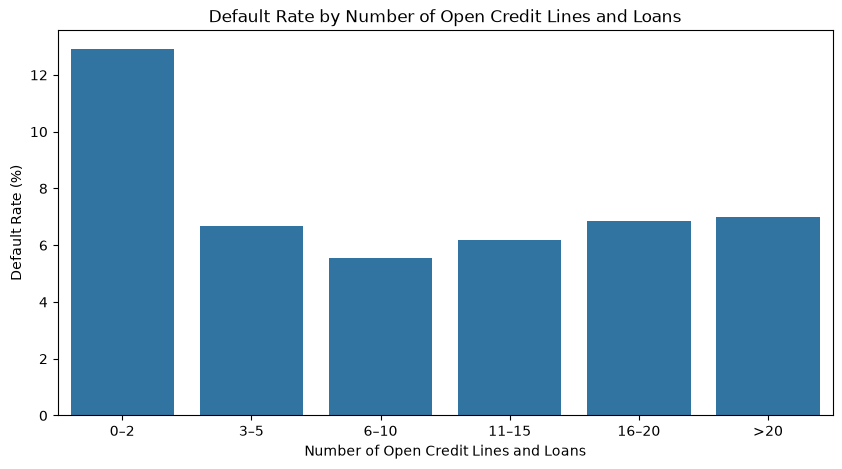

In [35]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=credit_lines_default.index,
    y=credit_lines_default["default_rate_%"]
)

plt.title("Default Rate by Number of Open Credit Lines and Loans")
plt.xlabel("Number of Open Credit Lines and Loans")
plt.ylabel("Default Rate (%)")

plt.show()

### Business Finding

The number of open credit lines and loans shows a non-linear relationship with default risk.

Customers with **0–2 open credit lines have the highest default rate of 12.92%**, while the default rate falls to **5.54% among customers with 6–10 open credit lines**.

Beyond 10 open credit lines, the default rate increases slightly but remains around 6–7%.

Therefore, having very few open credit lines is associated with higher default risk in this dataset, while having a larger number of credit lines does not show a similarly strong increase in risk.

# 8. Real Estate Loans and Default Risk

## Business Question

Does the number of real-estate loans or lines held by a customer influence the likelihood of default?

Multiple real-estate loans may indicate greater financial obligations. However, they may also reflect greater asset ownership or established borrowing capacity.

We will analyze default rates across different numbers of real-estate loans or lines to determine whether this feature is associated with credit risk.

In [37]:
credit_clean["RealEstateLoanGroup"] = pd.cut(
    credit_clean["NumberRealEstateLoansOrLines"],
    bins=[-1, 0, 1, 2, 3, float("inf")],
    labels=[
        "0",
        "1",
        "2",
        "3",
        "4+"
    ]
)

In [38]:
realestate_default = (
    credit_clean.groupby(
        "RealEstateLoanGroup",
        observed=True
    )["SeriousDlqin2yrs"]
    .agg(["count", "sum", "mean"])
)

realestate_default["default_rate_%"] = (
    realestate_default["mean"] * 100
).round(2)

realestate_default

,count,sum,mean,default_rate_%
RealEstateLoanGroup,,,,
0,56188,4672,0.083149,8.31
1,52338,2748,0.052505,5.25
2,31521,1765,0.055994,5.60
3,6300,422,0.066984,6.70
4+,3652,419,0.114732,11.47


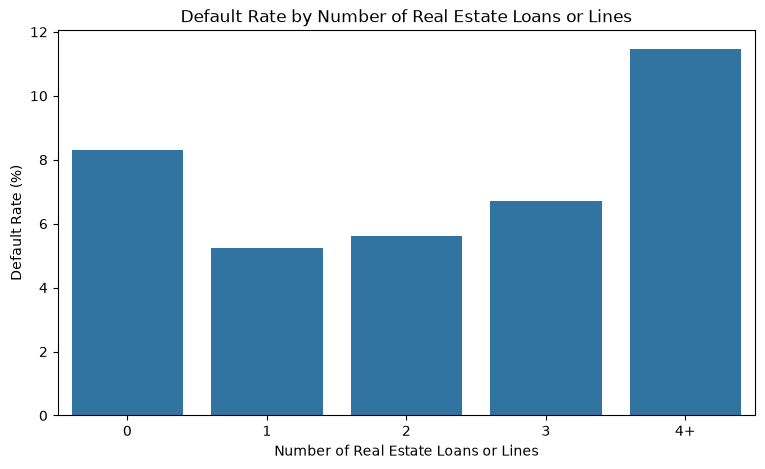

In [39]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=realestate_default.index,
    y=realestate_default["default_rate_%"]
)

plt.title("Default Rate by Number of Real Estate Loans or Lines")
plt.xlabel("Number of Real Estate Loans or Lines")
plt.ylabel("Default Rate (%)")

plt.show()

In [40]:
realestate_default

,count,sum,mean,default_rate_%
RealEstateLoanGroup,,,,
0,56188,4672,0.083149,8.31
1,52338,2748,0.052505,5.25
2,31521,1765,0.055994,5.60
3,6300,422,0.066984,6.70
4+,3652,419,0.114732,11.47


### Business Finding

The number of real-estate loans or lines shows a non-linear relationship with default risk.

Customers with **1 real-estate loan have the lowest default rate of 5.25%**, with customers having 2 loans showing a similar rate of 5.60%.

Default risk is higher among customers with **no real-estate loans (8.31%)** and increases further to **11.47% among customers with 4 or more real-estate loans**.

Therefore, the relationship is not simply "more real-estate loans means higher risk." Instead, customers with 1–2 loans show the lowest observed default rates, while both zero and very high numbers of real-estate loans are associated with higher default risk.

# 9. Dependents and Default Risk

## Business Question

Does the number of dependents a customer has influence the likelihood of default?

A larger number of dependents may indicate greater household financial responsibilities and potentially higher financial pressure.

We will analyze default rates across different numbers of dependents to determine whether this variable is associated with credit risk.

In [41]:
credit_clean["NumberOfDependents"].value_counts().sort_index()

NumberOfDependents
0.0     90826
1.0     26316
2.0     19521
3.0      9483
4.0      2862
5.0       746
6.0       158
7.0        51
8.0        24
9.0         5
10.0        5
13.0        1
20.0        1
Name: count, dtype: int64

In [42]:
credit_clean["DependentsGroup"] = pd.cut(
    credit_clean["NumberOfDependents"],
    bins=[-1, 0, 1, 2, 3, float("inf")],
    labels=[
        "0",
        "1",
        "2",
        "3",
        "4+"
    ]
)

In [44]:
dependents_default = (
    credit_clean.groupby(
        "DependentsGroup",
        observed=True
    )["SeriousDlqin2yrs"]
    .agg(["count", "sum", "mean"])
)

dependents_default["default_rate_%"] = (
    dependents_default["mean"] * 100
).round(2)

dependents_default

,count,sum,mean,default_rate_%
DependentsGroup,,,,
0,90826,5274,0.058067,5.81
1,26316,1935,0.073529,7.35
2,19521,1584,0.081143,8.11
3,9483,837,0.088263,8.83
4+,3853,396,0.102777,10.28


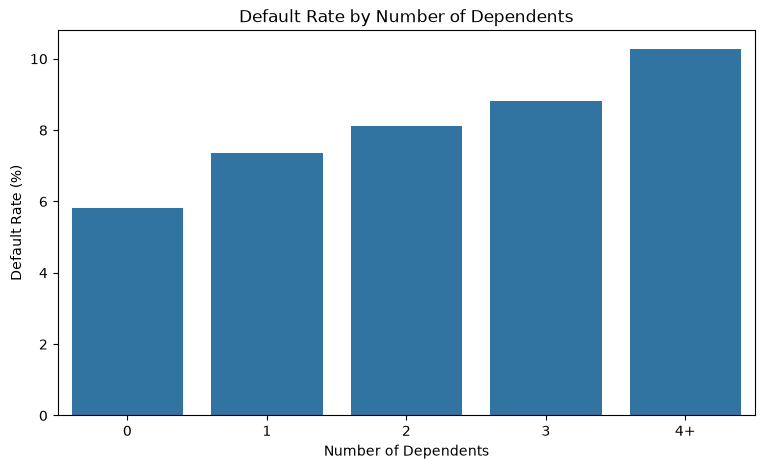

In [45]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=dependents_default.index,
    y=dependents_default["default_rate_%"]
)

plt.title("Default Rate by Number of Dependents")
plt.xlabel("Number of Dependents")
plt.ylabel("Default Rate (%)")

plt.show()

### Business Finding

The number of dependents shows a positive association with default risk.

The default rate increases consistently from **5.81% among customers with no dependents to 10.28% among customers with 4 or more dependents**.

This suggests that customers with greater household responsibilities may face higher financial pressure, which is associated with increased default risk in this dataset.

Overall, the number of dependents appears to provide useful information about a customer's credit risk, although the relationship should be interpreted as an association rather than a causal effect.


# Overall Business Findings

The Business EDA was conducted to identify customer characteristics and financial behaviors associated with the likelihood of serious delinquency within the next two years.

### 1. Previous Payment Behavior is a Strong Risk Indicator

Customers with previous payment delinquency show substantially higher default rates. The relationship becomes stronger as delinquency severity increases, with 90+ day delinquency showing the strongest association with future default.

### 2. Credit Utilization is Strongly Associated with Default

Default rates increase significantly as revolving credit utilization increases. The default rate rises from 1.81% for utilization between 0–0.1 to 40.10% for utilization between 1–2. This indicates that high utilization is an important indicator of financial stress and credit risk.

### 3. Younger Customers Show Higher Default Rates

Default rates decrease consistently with age. Customers aged 21–30 have the highest observed default rate of approximately 11.56%, while customers aged 81+ have a default rate of approximately 2.03%.

### 4. Lower Income is Associated with Higher Default Risk

Customers in the lowest income group show higher default rates than customers with higher monthly income. The default rate decreases from approximately 9.21% in the lowest income group to 4.62% in the highest income group.

### 5. Household Dependents Show a Positive Association with Risk

Default rates increase with the number of dependents. Customers with no dependents have a default rate of 5.81%, compared with 10.28% among customers with 4 or more dependents.

### 6. Several Financial Variables Have Non-Linear Relationships

DebtRatio, number of open credit lines, and number of real-estate loans show non-linear or irregular relationships with default. Therefore, assuming that higher values always correspond to higher risk would be inappropriate.

### 7. Overall Business Insight

The analysis suggests that default risk is influenced by a combination of **previous repayment behavior, credit utilization, age, income, and household financial responsibilities** rather than by a single factor.

The strongest observed signals in the Business EDA are **previous delinquency history and revolving credit utilization**. These findings will guide the subsequent feature engineering and model development stages.